<div align="center">

# **Penerapan Prompt AI untuk Analisis dan Interpretasi Data Geofisika**

<br>

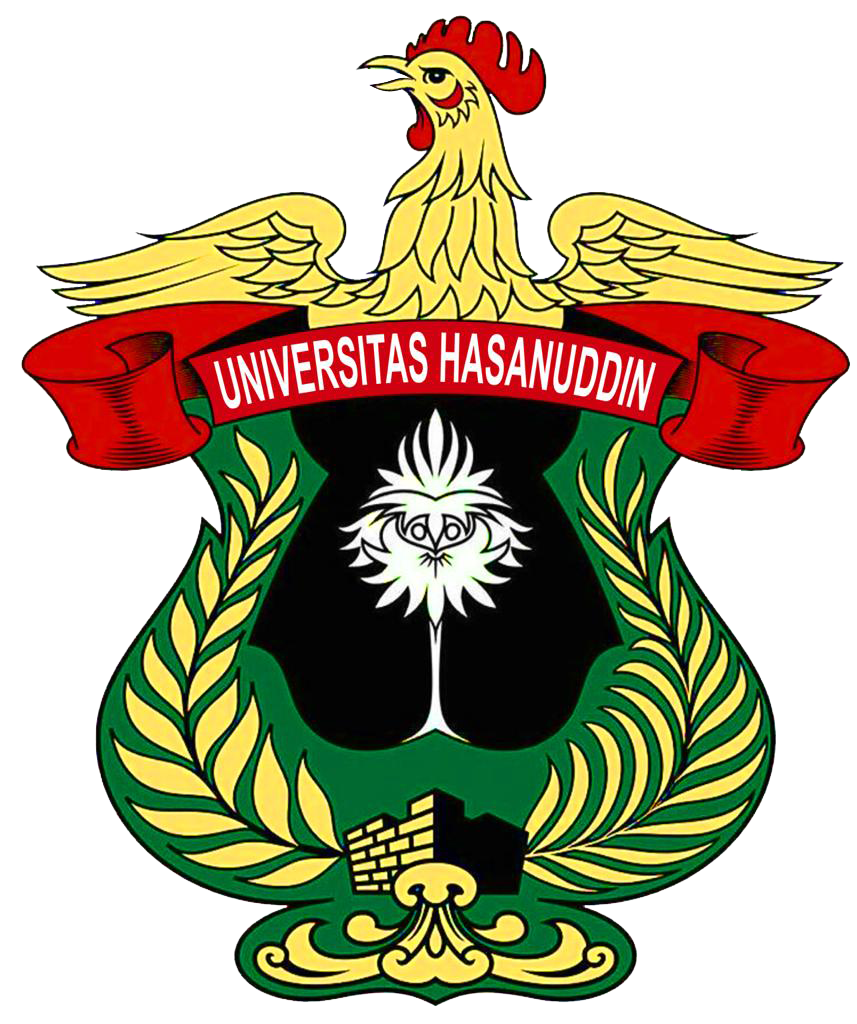

<br>

**TUGAS MATA KULIAH KECERDASAN ARTIFISIAL**  
**SUMBER: AI COOKBOOK UNTUK EARTH SCIENCES**

<br>

**Disusun oleh:**  

**SITTI AISYAH**  
**NIM: H061241073**

<br>

**PROGRAM STUDI GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**

<br>

**MAKASSAR**  
**2026**

</div>

## **KASUS 1 — INTERPRETASI PENAMPANG SEISMIK 2D**

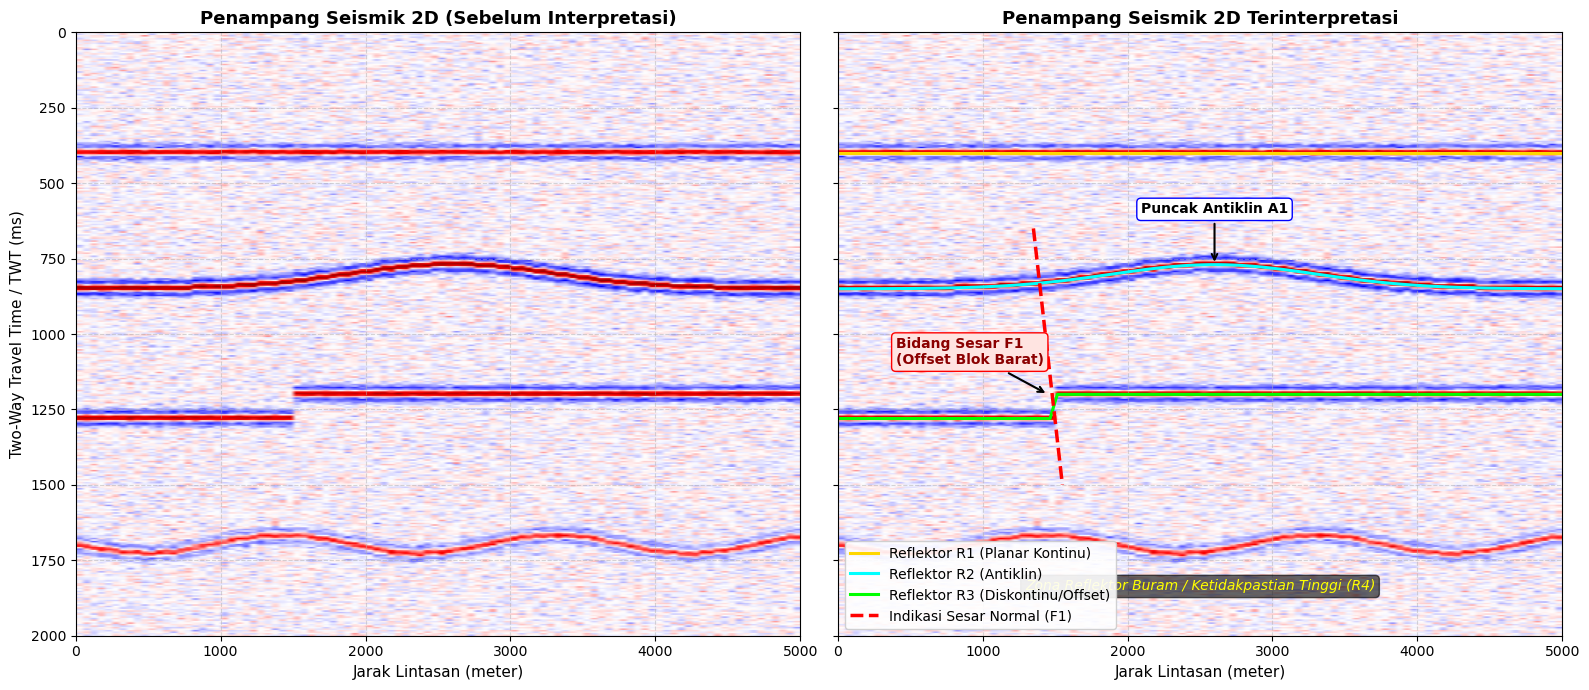

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

# Parameter Dimensi
n_traces = 100               # 100 trace seismik
n_samples = 400              # 400 sampel waktu
time = np.linspace(0, 2.0, n_samples)       # TWT (detik): 0 - 2.0 s (0 - 2000 ms)
distance = np.linspace(0, 5000, n_traces)   # Jarak lintasan (meter): 0 - 5000 m

# Matriks koefisien refleksi (Reflectivity model)
reflectivity = np.zeros((n_samples, n_traces))

# Horizon R1: Mendatar di ~0.4 s (400 ms)
r1_idx = int(0.4 / (time[1] - time[0]))
reflectivity[r1_idx, :] = 0.5

# Horizon R2: Terlipat (Antiklin) di sekitar tengah penampang (~0.8 s)
for i, dist in enumerate(distance):
    fold = 0.08 * np.exp(-((dist - 2600) / 1000)**2)  # Bentuk kubah
    t_val = 0.85 - fold
    idx = int(t_val / (time[1] - time[0]))
    if 0 <= idx < n_samples:
        reflectivity[idx, i] = 0.7

# Horizon R3: Terkena Sesar di lateral ~1500 m (~1.2 s)
for i, dist in enumerate(distance):
    # Offset sesar normal di lateral < 1500 m
    offset = 0.08 if dist < 1500 else 0.0
    t_val = 1.2 + offset
    idx = int(t_val / (time[1] - time[0]))
    if 0 <= idx < n_samples:
        reflectivity[idx, i] = 0.6

# R4: Acoustic Basement bergelombang di ~1.7 s
for i, dist in enumerate(distance):
    t_val = 1.7 + 0.03 * np.sin(dist / 300)
    idx = int(t_val / (time[1] - time[0]))
    if 0 <= idx < n_samples:
        reflectivity[idx, i] = 0.35

# Wavelet Ricker (Frekuensi dominan 25 Hz)
f_dom = 25
t_wav = np.linspace(-0.08, 0.08, 41)
wav = (1.0 - 2.0*(np.pi*f_dom*t_wav)**2) * np.exp(-(np.pi*f_dom*t_wav)**2)

# Konvolusi trace demi trace untuk membentuk penampang seismik 2D
seismic_section = np.zeros_like(reflectivity)
for i in range(n_traces):
    seismic_section[:, i] = np.convolve(reflectivity[:, i], wav, mode='same')

# Tambahkan sedikit noise acak untuk menyerupai data lapangan riil
noise = np.random.normal(0, 0.05, seismic_section.shape)
seismic_section += noise

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# Plot 1: Penampang Seismik Asli (Raw 2D Seismic)
ax1 = axes[0]
im1 = ax1.imshow(seismic_section, extent=[0, 5000, 2000, 0], aspect='auto', 
                 cmap='seismic', vmin=-0.8, vmax=0.8)
ax1.set_title("Penampang Seismik 2D (Sebelum Interpretasi)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Jarak Lintasan (meter)", fontsize=11)
ax1.set_ylabel("Two-Way Travel Time / TWT (ms)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Penampang Seismik Terinterpretasi (Interpreted)
ax2 = axes[1]
im2 = ax2.imshow(seismic_section, extent=[0, 5000, 2000, 0], aspect='auto', 
                 cmap='seismic', vmin=-0.8, vmax=0.8)

# Overlay Hasil Picking Reflektor
t_r1 = np.full_like(distance, 400)
t_r2 = (0.85 - 0.08 * np.exp(-((distance - 2600) / 1000)**2)) * 1000
t_r3 = (1.2 + np.where(distance < 1500, 0.08, 0.0)) * 1000

ax2.plot(distance, t_r1, color='gold', linewidth=2.2, label='Reflektor R1 (Planar Kontinu)')
ax2.plot(distance, t_r2, color='cyan', linewidth=2.2, label='Reflektor R2 (Antiklin)')
ax2.plot(distance, t_r3, color='lime', linewidth=2.2, label='Reflektor R3 (Diskontinu/Offset)')

# Garis Sesar (Fault F1)
fault_x = [1350, 1550]
fault_t = [650, 1500]
ax2.plot(fault_x, fault_t, color='red', linestyle='--', linewidth=2.5, label='Indikasi Sesar Normal (F1)')

# Anotasi Struktur
ax2.annotate('Puncak Antiklin A1', xy=(2600, 770), xytext=(2600, 600),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             ha='center', fontweight='bold', fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="b", lw=1))

ax2.annotate('Bidang Sesar F1\n(Offset Blok Barat)', xy=(1450, 1200), xytext=(400, 1100),
             arrowprops=dict(facecolor='red', arrowstyle='->', lw=1.5),
             fontweight='bold', fontsize=10, color='darkred', bbox=dict(boxstyle="round,pad=0.3", fc="mistyrose", ec="red"))

ax2.text(2500, 1850, 'Zona Reflektor Buram / Ketidakpastian Tinggi (R4)', 
         color='yellow', ha='center', fontsize=10, style='italic',
         bbox=dict(boxstyle="round", fc="black", alpha=0.6))

ax2.set_title("Penampang Seismik 2D Terinterpretasi", fontsize=13, fontweight='bold')
ax2.set_xlabel("Jarak Lintasan (meter)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower left', framealpha=0.9)

plt.tight_layout()
plt.show()




#### **Interpretasi Penampang Seismik 2D**

1 **Reflektor R1 (Garis Kuning, TWT ~400 ms):**  
* Bentuk datar horizontal dan sangat kontinu $\rightarrow$ Diinterpretasikan sebagai lapisan sedimen atas yang belum terdeformasi.

2 **Reflektor R2 / Antiklin A1 (Garis Sian, TWT 750–850 ms):**
* Melengkung cembung ke atas pada jarak 1.800–3.500 m $\rightarrow$ Diinterpretasikan sebagai struktur lipatan antiklin.

3 **Reflektor R3 (Garis Hijau, TWT 1.200–1.280 ms):**
* Terpotong dan bergeser vertikal (*offset* ~80 ms) di jarak ~1.500 m $\rightarrow$ Diinterpretasikan sebagai lapisan yang terdislokasi patahan.

4 **Sesar F1 (Garis Putus-Putus Merah):**
* Bidang patahan miring ke barat, blok barat relatif turun $\rightarrow$ Diinterpretasikan sebagai sesar normal (sesar turun). Sesar berhenti di bawah R1.

5 **Reflektor R4 (Zona Bawah, TWT >1.600 ms):**
* Refleksi buram dan sinyal melemah $\rightarrow$ Diperkirakan sebagai batuan dasar (*acoustic basement*) dengan ketidakpastian tinggi.

**Kesimpulan:**
 Bawah permukaan merekam deformasi tektonik berupa antiklin dan sesar turun di bagian tengah, yang kemudian ditutupi oleh lapisan datar di bagian atas. Litologi tidak ditentukan karena belum ada data sumur.


## **KASUS 2 — INTERPRETASI PENAMPANG RESISTIVITAS ERT 2D**

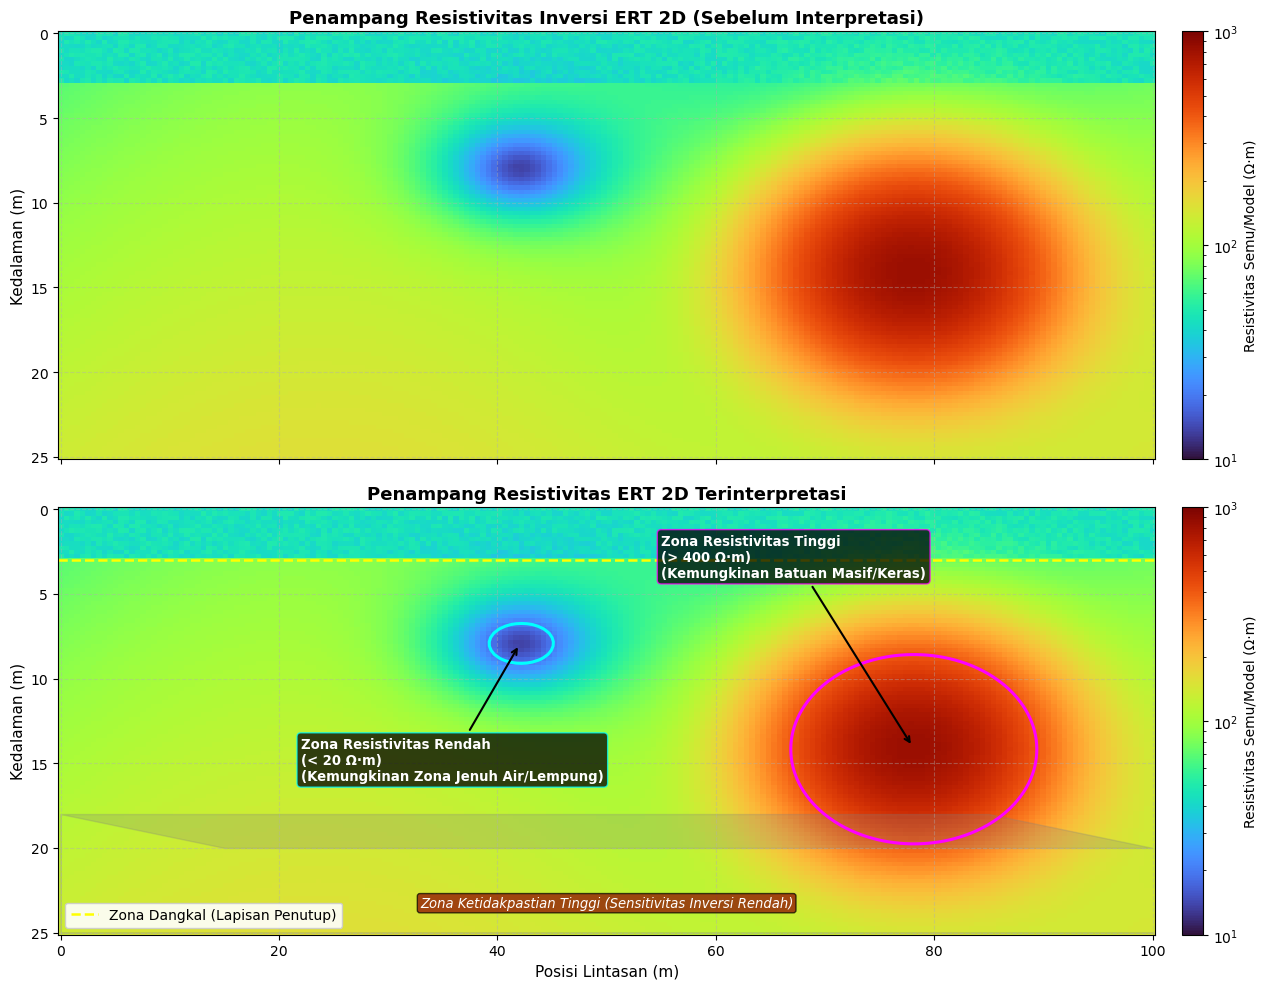

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd

np.random.seed(42)

# Dimensi penampang (Lintasan 0 - 100 m, Kedalaman 0 - 25 m)
x = np.linspace(0, 100, 200)
z = np.linspace(0, 25, 100)
X, Z = np.meshgrid(x, z)

# Model resistivitas latar belakang (gradasi sedang: 50 - 150 Ohm.m)
res = 60 + 3.0 * Z + 20 * np.sin(X / 15)

# Zona 1: Lapisan dangkal konduktif-sedang (0 - 3 m)
res[Z <= 3] = 40 + 10 * np.random.rand(*res[Z <= 3].shape)

# Anomali Konduktif (Resistivitas Sangat Rendah: < 15 Ohm.m di lateral 30-55 m, kedalaman 4-13 m)
anomali_rendah = np.exp(-(((X - 42) / 10)**2 + ((Z - 8) / 4)**2))
res = res * (1 - 0.85 * anomali_rendah)

# Anomali Resistif (Resistivitas Tinggi: > 500 Ohm.m di lateral 65-90 m, kedalaman 6-22 m)
anomali_tinggi = np.exp(-(((X - 78) / 12)**2 + ((Z - 14) / 6)**2))
res = res + 750 * anomali_tinggi

# Tambahkan efek penurunan resolusi inversi di bagian tepi dan dalam (smoothing)
res = np.clip(res, 5, 1200)

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Subplot 1: Penampang Inversi ERT 2D Asli
ax1 = axes[0]
c1 = ax1.pcolormesh(X, Z, res, shading='auto', cmap='turbo', norm=LogNorm(vmin=10, vmax=1000))
ax1.invert_yaxis()
ax1.set_title("Penampang Resistivitas Inversi ERT 2D (Sebelum Interpretasi)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Kedalaman (m)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.4)
cb1 = fig.colorbar(c1, ax=ax1, orientation='vertical', pad=0.02)
cb1.set_label("Resistivitas Semu/Model (Ω·m)", fontsize=10)

# Subplot 2: Penampang ERT Terinterpretasi
ax2 = axes[1]
c2 = ax2.pcolormesh(X, Z, res, shading='auto', cmap='turbo', norm=LogNorm(vmin=10, vmax=1000))
ax2.invert_yaxis()

# Delineasi Zona Anomali
# 1. Lapisan Penutup Dangkal (Garis Kuning)
ax2.axhline(3, color='yellow', linestyle='--', linewidth=1.8, label='Zona Dangkal (Lapisan Penutup)')

# 2. Anomali Resistivitas Rendah (Garis Cyan)
cs1 = ax2.contour(X, Z, res, levels=[20], colors='cyan', linewidths=2.2)
ax2.annotate('Zona Resistivitas Rendah\n(< 20 Ω·m)\n(Kemungkinan Zona Jenuh Air/Lempung)', 
             xy=(42, 8), xytext=(22, 16),
             arrowprops=dict(facecolor='cyan', arrowstyle='->', lw=1.5),
             fontweight='bold', fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", fc="black", alpha=0.75, ec="cyan"), color='white')

# 3. Anomali Resistivitas Tinggi (Garis Magenta)
cs2 = ax2.contour(X, Z, res, levels=[400], colors='magenta', linewidths=2.2)
ax2.annotate('Zona Resistivitas Tinggi\n(> 400 Ω·m)\n(Kemungkinan Batuan Masif/Keras)', 
             xy=(78, 14), xytext=(55, 4),
             arrowprops=dict(facecolor='magenta', arrowstyle='->', lw=1.5),
             fontweight='bold', fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", fc="black", alpha=0.75, ec="magenta"), color='white')

# Zona Penurunan Sensitivitas / Ketidakpastian (Tepi & Bawah)
ax2.fill_between([0, 15, 100, 85, 0], [25, 25, 25, 25, 25], [18, 20, 20, 18, 18], color='gray', alpha=0.25)
ax2.text(50, 23.5, 'Zona Ketidakpastian Tinggi (Sensitivitas Inversi Rendah)', 
         color='white', ha='center', fontsize=9.5, style='italic',
         bbox=dict(boxstyle="round,pad=0.2", fc="darkred", alpha=0.7))

ax2.set_title("Penampang Resistivitas ERT 2D Terinterpretasi", fontsize=13, fontweight='bold')
ax2.set_xlabel("Posisi Lintasan (m)", fontsize=11)
ax2.set_ylabel("Kedalaman (m)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='lower left', framealpha=0.9)
cb2 = fig.colorbar(c2, ax=ax2, orientation='vertical', pad=0.02)
cb2.set_label("Resistivitas Semu/Model (Ω·m)", fontsize=10)

plt.tight_layout()
plt.show()



#### **Interpretasi Penampang Resistivitas ERT 2D**

1 **Zona Dangkal (Garis Putus-Putus Kuning, Kedalaman 0 – 3 m):**
* Nilai resistivitas sedang (30 – 60 Ω·m, warna toska/hijau) di sepanjang lintasan $\rightarrow$ Diinterpretasikan sebagai lapisan tanah penutup (*topsoil*) atau zona lapuk.

2 **Zona Resistivitas Rendah (Lingkaran Cyan, Lateral 35 – 50 m, Kedalaman 6 – 10 m):**
* Nilai resistivitas sangat rendah (< 20 Ω·m, warna biru tua/ungu) $\rightarrow$ Diinterpretasikan sebagai zona anomali konduktif (kemungkinan zona jenuh air tanah atau lensa lempung).

3 **Zona Resistivitas Tinggi (Lingkaran Magenta, Lateral 65 – 90 m, Kedalaman 8 – 20 m):**
* Nilai resistivitas sangat tinggi (> 400 Ω·m, warna merah pekat) $\rightarrow$ Diinterpretasikan sebagai zona anomali resistif (kemungkinan batuan keras/masif yang belum lapuk).

4 **Zona Bawah & Sudut (Area Transparan Abu-Abu, Kedalaman > 18 m):**
* Pola kontur melebar $\rightarrow$ Merupakan zona ketidakpastian tinggi akibat penurunan sensitivitas penetrasi arus inversi di bagian dasar dan tepi.

**Kesimpulan:**
* Penampang menunjukkan kontras sifat listrik yang jelas: zona konduktif (basah/lempung) di sisi tengah-kiri dan tubuh resistif padat di sisi kanan. 
* Litologi batuan definitif tidak ditentukan karena memerlukan data validasi pemboran.


## **KASUS 3 — PEMETAAN KERAWANAN LONGSOR MENGGUNAKAN SIG**

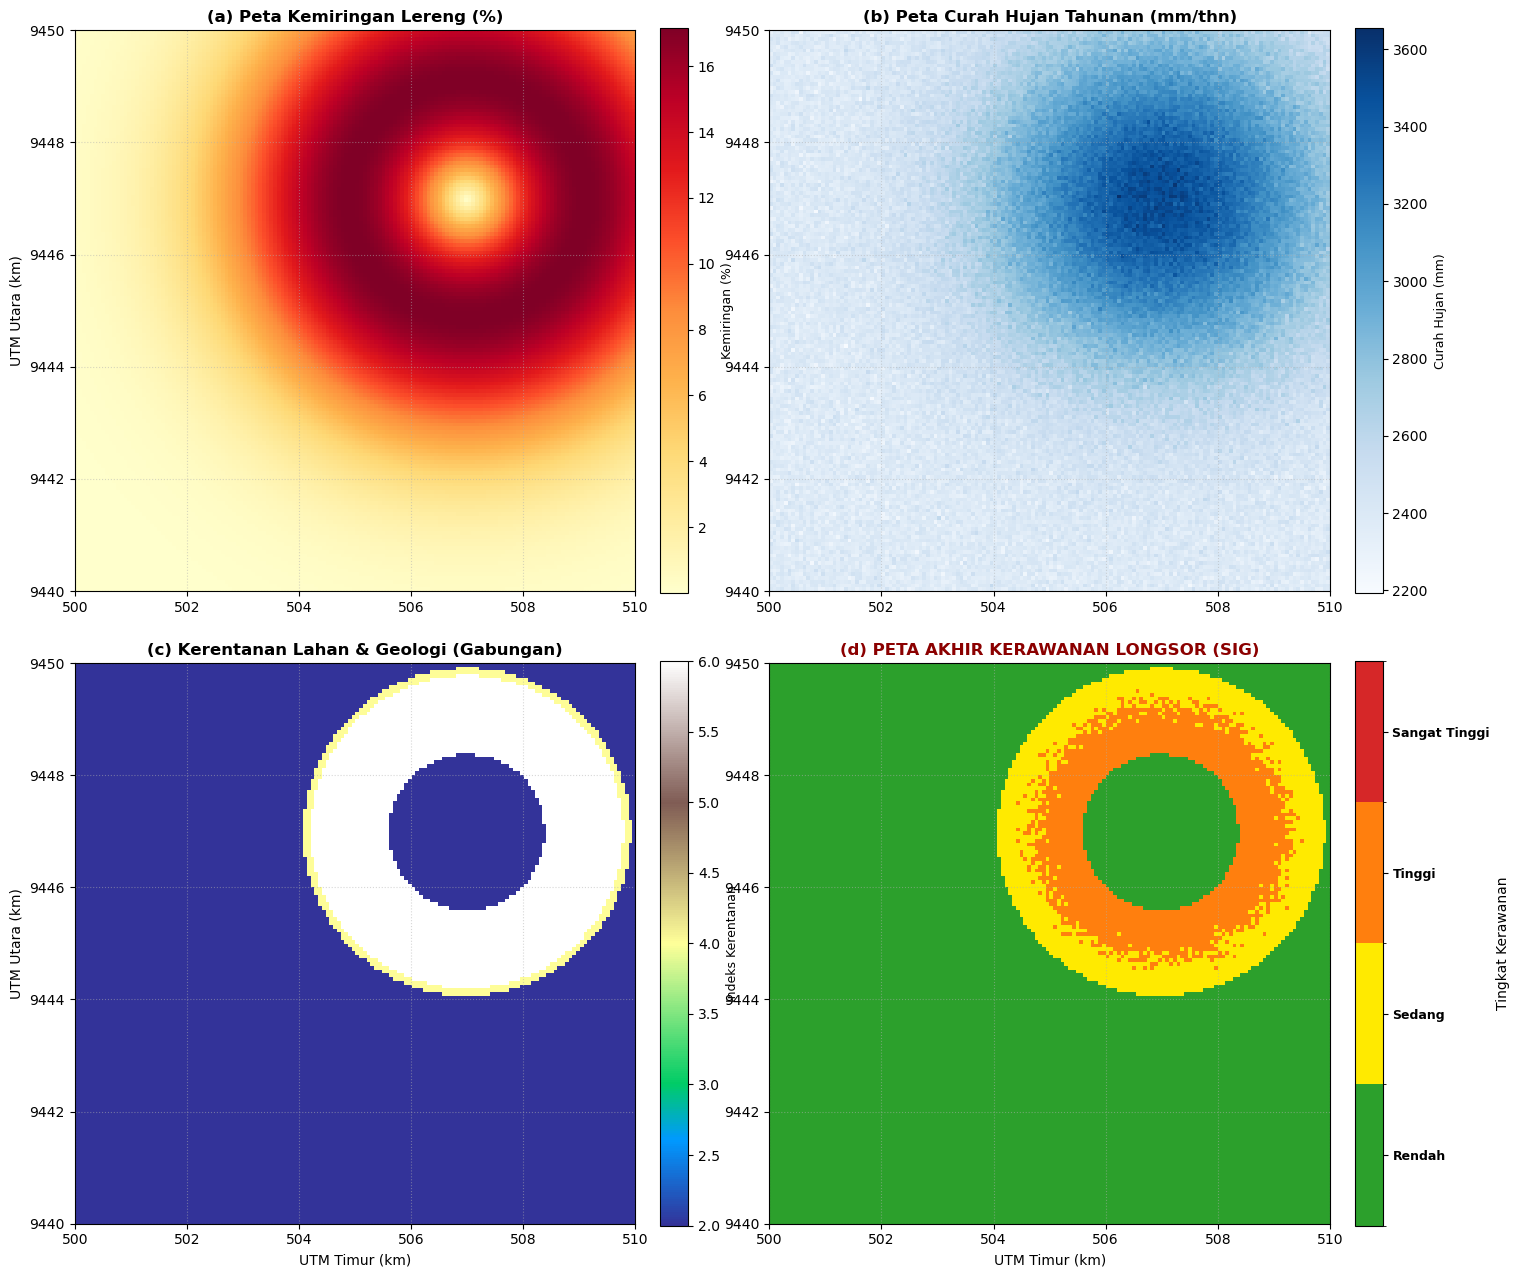

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

np.random.seed(42)
grid_size = 150  # Resolusi 150x150 pixel
x = np.linspace(500000, 510000, grid_size)  # Koordinat UTM Timur (m)
y = np.linspace(9440000, 9450000, grid_size)  # Koordinat UTM Utara (m)
X, Y = np.meshgrid(x, y)

# 1. Elevasi & Kemiringan Lereng (Slope dalam %)
# Perbukitan di bagian timur laut (curam) dan dataran di barat daya
dem = 200 + 600 * np.exp(-(((X - 507000)/3000)**2 + ((Y - 9447000)/3000)**2))
dy, dx = np.gradient(dem, y[1]-y[0], x[1]-x[0])
slope = np.sqrt(dx**2 + dy**2) * 100  # Kemiringan lereng (%)
slope = np.clip(slope, 0, 70)

# Skor Kemiringan Lereng (Bobot 35%)
score_slope = np.where(slope < 15, 1, np.where(slope < 30, 2, np.where(slope < 45, 3, 4)))

# 2. Curah Hujan Tahunan (mm/tahun) (Bobot 25%)
rainfall = 2000 + 1500 * (dem / np.max(dem)) + np.random.normal(0, 50, dem.shape)
score_rain = np.where(rainfall < 2500, 1, np.where(rainfall < 3000, 2, np.where(rainfall < 3300, 3, 4)))

# 3. Penggunaan Lahan (Bobot 20%)
# 1: Hutan lebat, 2: Perkebunan, 3: Tegalan/Semak, 4: Pemukiman di lereng
landuse_score = np.ones_like(dem)
landuse_score[dem > 400] = 2  # Hutan/Kebun lereng
landuse_score[(slope > 25) & (dem < 500)] = 4  # Lahan terbuka/pemukiman lereng
landuse_score[slope <= 15] = 1  # Dataran aman

# 4. Litologi / Geologi (Bobot 20%)
# 1: Aluvium dataran, 2: Sedimen padat, 3: Batuan vulkanik lapuk di perbukitan
geology_score = np.where(slope < 15, 1, np.where(dem < 450, 2, 4))

# Rumus: 35% Lereng + 25% Hujan + 20% Lahan + 20% Geologi
total_index = (0.35 * score_slope) + (0.25 * score_rain) + (0.20 * landuse_score) + (0.20 * geology_score)

# Klasifikasi Kerawanan Akhir (1: Rendah, 2: Sedang, 3: Tinggi, 4: Sangat Tinggi)
landslide_class = np.zeros_like(total_index)
landslide_class[total_index < 1.8] = 1   # Rendah
landslide_class[(total_index >= 1.8) & (total_index < 2.6)] = 2  # Sedang
landslide_class[(total_index >= 2.6) & (total_index < 3.3)] = 3  # Tinggi
landslide_class[total_index >= 3.3] = 4  # Sangat Tinggi


fig, axes = plt.subplots(2, 2, figsize=(15, 13))

# Peta A: Kemiringan Lereng
ax1 = axes[0, 0]
im1 = ax1.imshow(slope, extent=[500, 510, 9440, 9450], cmap='YlOrRd', origin='lower')
ax1.set_title("(a) Peta Kemiringan Lereng (%)", fontsize=12, fontweight='bold')
ax1.set_ylabel("UTM Utara (km)", fontsize=10)
cb1 = plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
cb1.set_label("Kemiringan (%)", fontsize=9)

# Peta B: Curah Hujan
ax2 = axes[0, 1]
im2 = ax2.imshow(rainfall, extent=[500, 510, 9440, 9450], cmap='Blues', origin='lower')
ax2.set_title("(b) Peta Curah Hujan Tahunan (mm/thn)", fontsize=12, fontweight='bold')
cb2 = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
cb2.set_label("Curah Hujan (mm)", fontsize=9)

# Peta C: Penggunaan Lahan & Geologi
ax3 = axes[1, 0]
im3 = ax3.imshow(landuse_score + geology_score, extent=[500, 510, 9440, 9450], cmap='terrain', origin='lower')
ax3.set_title("(c) Kerentanan Lahan & Geologi (Gabungan)", fontsize=12, fontweight='bold')
ax3.set_xlabel("UTM Timur (km)", fontsize=10)
ax3.set_ylabel("UTM Utara (km)", fontsize=10)
cb3 = plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
cb3.set_label("Indeks Kerentanan", fontsize=9)

# Peta D: PETA AKHIR KERAWANAN LONGSOR
ax4 = axes[1, 1]
cmap_res = ListedColormap(['#2ca02c', '#ffea00', '#ff7f0e', '#d62728'])  # Hijau, Kuning, Oranye, Merah
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], cmap_res.N)

im4 = ax4.imshow(landslide_class, extent=[500, 510, 9440, 9450], cmap=cmap_res, norm=norm, origin='lower')
ax4.set_title("(d) PETA AKHIR KERAWANAN LONGSOR (SIG)", fontsize=12, fontweight='bold', color='darkred')
ax4.set_xlabel("UTM Timur (km)", fontsize=10)

# Colorbar Kategori
cb4 = plt.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04, ticks=[1, 2, 3, 4])
cb4.ax.set_yticklabels(['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'], fontsize=9, fontweight='bold')
cb4.set_label("Tingkat Kerawanan", fontsize=10)

for ax in axes.flat:
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


#### **Interpretasi Peta Kerawanan Longsor Berbasis SIG**

1 **Parameter Kemiringan Lereng (Peta a):**
* Lereng curam (> 30 – 45%, warna jingga-merah) terkonsentrasi di timur laut, menjadi faktor pemicu gravitasi paling dominan (bobot 35%).

2 **Parameter Curah Hujan (Peta b):**
* Curah hujan tertinggi (> 3.000 mm/tahun, warna biru tua) berada di wilayah elevasi tinggi/perbukitan, meningkatkan potensi penjenuhan pori tanah (bobot 25%).

3 **Parameter Lahan & Geologi (Peta c):**
* Zona perbukitan dengan tutupan lahan terbuka/pemukiman lereng dan batuan lapuk memperlemah stabilitas lereng (bobot gabungan 40%).

4 **Peta Akhir Kerawanan Longsor (Peta d):**
* Zona Kerawanan Rendah (Hijau): Terletak di barat daya (wilayah dataran datar dengan lereng < 15%).
* Zona Kerawanan Sedang (Kuning): Zona transisi bergelombang melandai di bagian tengah.
* Zona Kerawanan Tinggi & Sangat Tinggi (Oranye & Merah): Terpusat di timur laut akibat akumulasi lereng curam, curah hujan tinggi, dan formasi batuan lereng.

**Kesimpulan:**
* Potensi kerawanan longsor meningkat signifikan ke arah timur laut sesuai pola geomorfologi lereng dan curah hujan.
* Peta ini merupakan model spasial perkiraan potensi kerawanan, bukan penentu kejadian longsor aktual di lapangan.


## **KASUS 4 — ANALISIS POLA CURAH HUJAN**

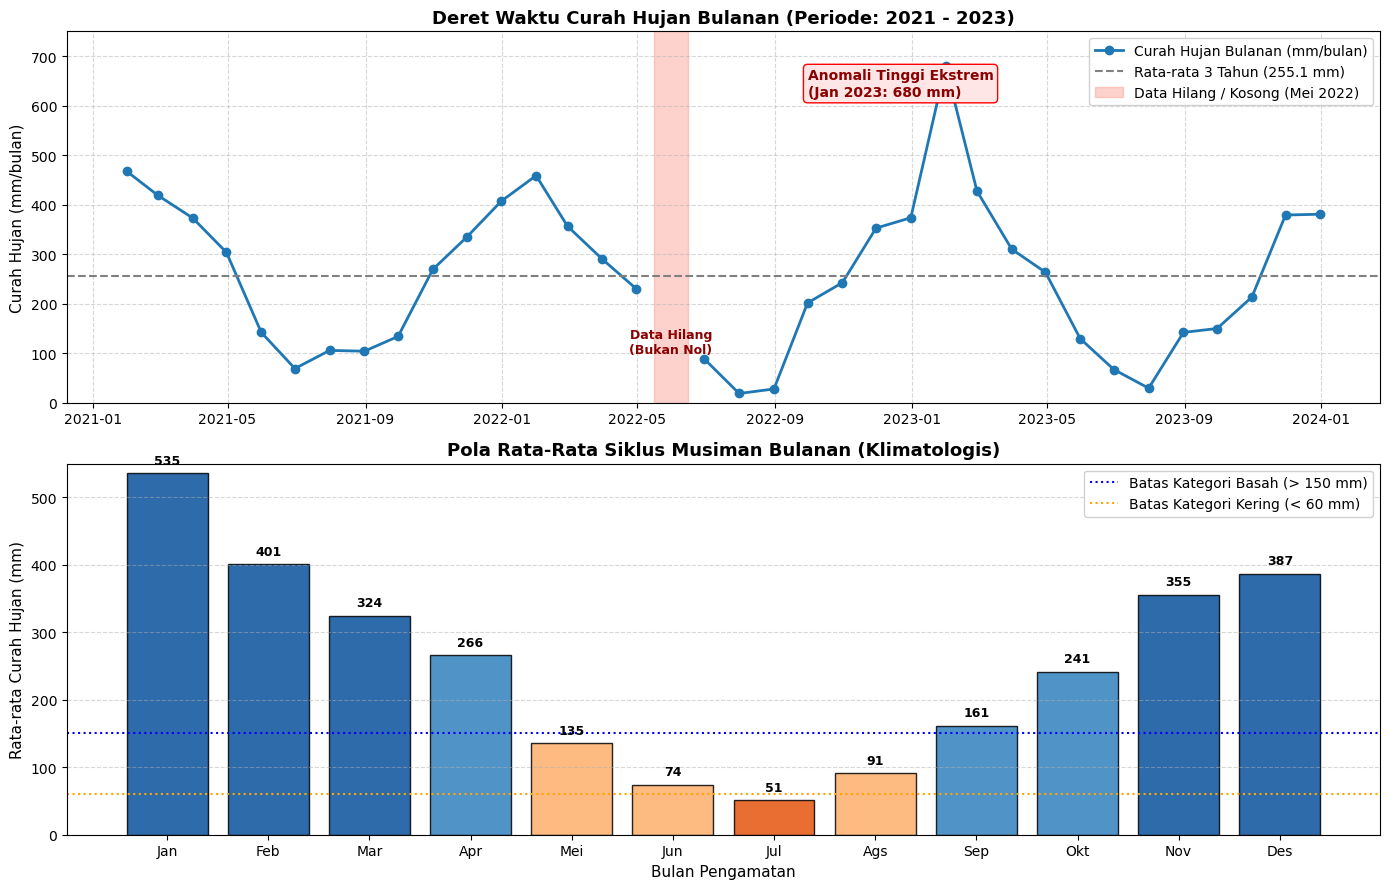

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

# Periode analisis: 36 bulan (Januari 2021 - Desember 2023)
dates = pd.date_range(start="2021-01-01", periods=36, freq='ME')

# Konversi bulan ke array numpy murni agar bisa diedit
month_indices = np.array(dates.month)
baseline_cycle = 250 + 200 * np.cos(2 * np.pi * (month_indices - 1) / 12)
noise = np.random.normal(0, 35, size=36)

# Pastikan tipe data array float murni
rainfall = np.array(baseline_cycle + noise, dtype=float)
rainfall = np.clip(rainfall, 10, None)

# 1. Anomali Ekstrem: Hujan sangat lebat di Januari 2023 (> 650 mm)
rainfall[24] = 680.0  

# 2. Data Hilang (Missing Data / NaN): Pengamatan Mei 2022 tidak tercatat (sensor error)
rainfall[16] = np.nan  

# Buat DataFrame
df_rain = pd.DataFrame({'Tanggal': dates, 'Curah_Hujan_mm': rainfall})

# Hitung Rata-Rata Siklus Bulanan (Klimatologi 12 Bulan)
monthly_avg = df_rain.groupby(df_rain['Tanggal'].dt.month)['Curah_Hujan_mm'].mean()
months_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Ags', 'Sep', 'Okt', 'Nov', 'Des']

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Plot 1: Deret Waktu Curah Hujan (Time Series)
ax1 = axes[0]
ax1.plot(df_rain['Tanggal'], df_rain['Curah_Hujan_mm'], marker='o', color='#1f77b4', 
         linewidth=2, label='Curah Hujan Bulanan (mm/bulan)')

# Garis Rata-rata Keseluruhan
mean_val = df_rain['Curah_Hujan_mm'].mean()
ax1.axhline(mean_val, color='gray', linestyle='--', linewidth=1.5, label=f'Rata-rata 3 Tahun ({mean_val:.1f} mm)')

# Anotasi Anomali Ekstrem
ax1.annotate('Anomali Tinggi Ekstrem\n(Jan 2023: 680 mm)', 
             xy=(df_rain['Tanggal'].iloc[24], df_rain['Curah_Hujan_mm'].iloc[24]), 
             xytext=(df_rain['Tanggal'].iloc[20], 620),
             arrowprops=dict(facecolor='red', arrowstyle='->', lw=1.5),
             fontweight='bold', color='darkred', bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="red"))

# Penanda Data Kosong (Missing Data)
missing_date = df_rain['Tanggal'].iloc[16]
ax1.axvspan(missing_date - pd.Timedelta(days=15), missing_date + pd.Timedelta(days=15), 
            color='salmon', alpha=0.35, label='Data Hilang / Kosong (Mei 2022)')
ax1.text(missing_date, 100, 'Data Hilang\n(Bukan Nol)', ha='center', fontsize=9, fontweight='bold', color='darkred')

ax1.set_title("Deret Waktu Curah Hujan Bulanan (Periode: 2021 - 2023)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Curah Hujan (mm/bulan)", fontsize=11)
ax1.set_ylim(0, 750)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', framealpha=0.9)

# Plot 2: Pola Siklus Musiman Rata-Rata Bulanan
ax2 = axes[1]
colors = ['#08519c' if v >= 300 else '#3182bd' if v >= 150 else '#fdae6b' if v >= 70 else '#e6550d' for v in monthly_avg]
bars = ax2.bar(months_labels, monthly_avg, color=colors, edgecolor='black', alpha=0.85)

# Garis Batas Standar
ax2.axhline(150, color='blue', linestyle=':', linewidth=1.5, label='Batas Kategori Basah (> 150 mm)')
ax2.axhline(60, color='orange', linestyle=':', linewidth=1.5, label='Batas Kategori Kering (< 60 mm)')

# Label Nilai di Atas Bar
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 10, f'{yval:.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_title("Pola Rata-Rata Siklus Musiman Bulanan (Klimatologis)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Bulan Pengamatan", fontsize=11)
ax2.set_ylabel("Rata-rata Curah Hujan (mm)", fontsize=11)
ax2.set_ylim(0, 550)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
ax2.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()


#### **Interpretasi Pola Curah Hujan (2021 – 2023)**

1 **Periode Pengamatan dan Rata-Rata (Grafik Atas):**
* Data mencakup 36 bulan (Januari 2021 – Desember 2023) dengan rata-rata keseluruhan sebesar 255,1 mm/bulan.
* Terlihat fluktuasi berulang tahunan yang konsisten: curah hujan tinggi di awal tahun dan menurun di pertengahan tahun.

2 **Pola Siklus Musiman Bulanan (Grafik Bawah):**
* Periode Curah Hujan Tinggi (Musim Hujan): Terjadi pada November – April dengan nilai > 150 mm/bulan, puncaknya pada Januari (535 mm) dan Februari (401 mm).
* Periode Curah Hujan Rendah (Musim Kemarau): Terjadi pada Juni – Agustus, dengan curah hujan terendah pada Juli (51 mm) di bawah batas kering 60 mm.
* Pola ini mengindikasikan tipe curah hujan monsunal dengan satu periode basah dan satu periode kering yang tegas per tahun.

3 **Identifikasi Anomali Ekstrem (Grafik Atas):**
* Terdeteksi anomali tinggi ekstrem pada Januari 2023 mencapai 680 mm, melonjak signifikan jauh di atas rata-rata normal.

4 **Penanganan Data Kosong / Missing Data (Grafik Atas):**
* Terdapat data pengamatan yang hilang pada Mei 2022 (area merah). Data ini tidak diisi angka nol agar tidak merusak keaslian data dan nilai statistik.

**Kesimpulan:**
* Wilayah studi memiliki variasi musiman yang sangat kontras antara musim basah (DJF) dan musim kering (JAS).
* Penyebab fisis anomali ekstrem (seperti La Niña atau gangguan konvektif) tidak dapat ditentukan hanya dari data curah hujan tanpa parameter atmosfer pendukung.


## **KASUS 5 — ANALISIS SUHU PERMUKAAN LAUT**

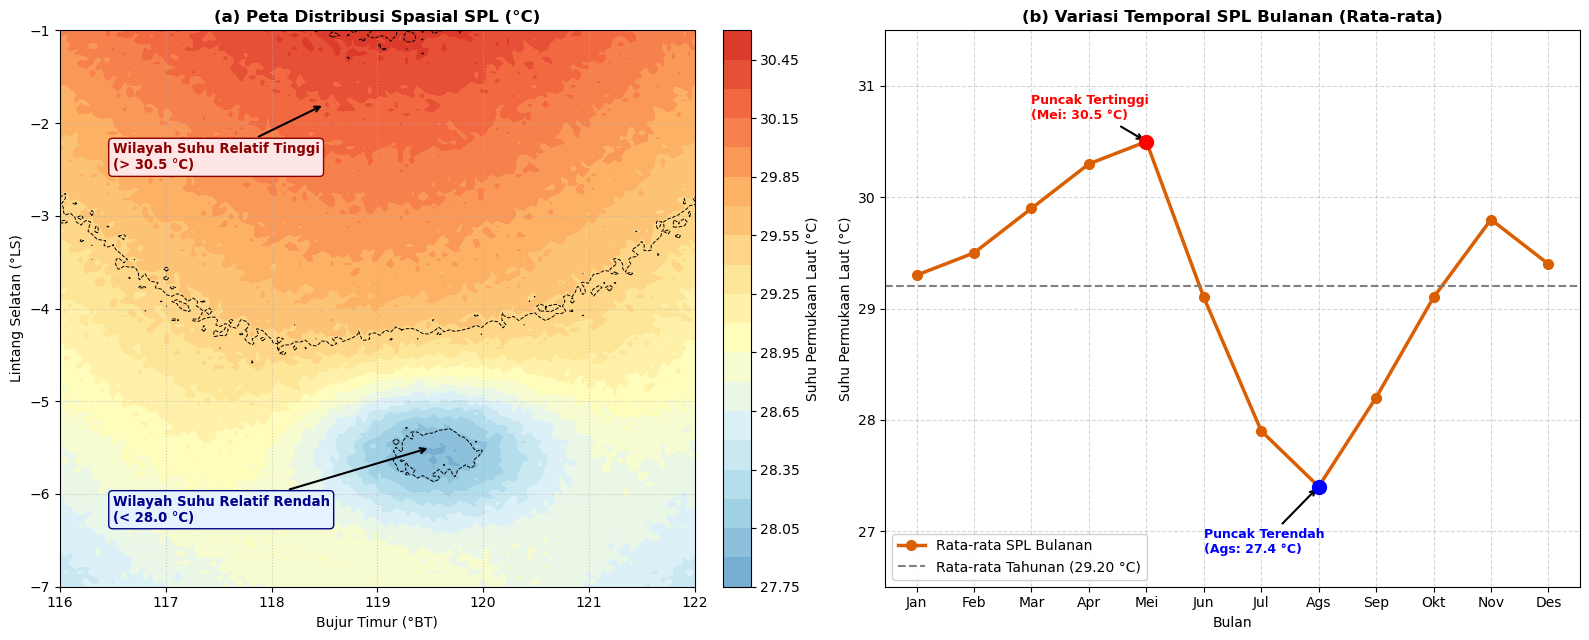

In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# A. Data Spasial (Resolusi Grid: 0.05° x 0.05°, Wilayah: 116° - 122° BT, 1° - 7° LS)
lons = np.linspace(116.0, 122.0, 120)  # Bujur Timur (°E)
lats = np.linspace(-7.0, -1.0, 120)    # Lintang (°S)
LON, LAT = np.meshgrid(lons, lats)

# Model Distribusi Spasial SPL (°C): Lebih hangat di utara, lebih dingin di selatan
sst_spatial = 29.2 + 0.8 * (LAT + 4.0) / 3.0 + 0.5 * np.sin((LON - 116) * np.pi / 6)

# Zona Suhu Rendah Lokal di Selatan (Perairan 119.5° BT, 5.5° LS)
upwelling_effect = 1.4 * np.exp(-(((LON - 119.5)/1.2)**2 + ((LAT - (-5.5))/0.8)**2))
sst_spatial = sst_spatial - upwelling_effect
sst_spatial += np.random.normal(0, 0.04, sst_spatial.shape)

# B. Data Temporal (Variasi Rata-rata Bulanan Jan - Des)
months = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Ags', 'Sep', 'Okt', 'Nov', 'Des']
sst_temporal = np.array([29.3, 29.5, 29.9, 30.3, 30.5, 29.1, 27.9, 27.4, 28.2, 29.1, 29.8, 29.4])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Plot 1: Peta Distribusi Spasial SPL
ax1 = axes[0]
contour = ax1.contourf(LON, LAT, sst_spatial, levels=25, cmap='RdYlBu_r', vmin=27.0, vmax=31.0)
ax1.contour(LON, LAT, sst_spatial, levels=[28.0, 29.5, 30.5], colors='black', linewidths=0.7, linestyles='--')

# Anotasi Wilayah Suhu Tinggi dan Rendah
ax1.annotate('Wilayah Suhu Relatif Tinggi\n(> 30.5 °C)', xy=(118.5, -1.8), xytext=(116.5, -2.5),
             arrowprops=dict(facecolor='darkred', arrowstyle='->', lw=1.5),
             fontweight='bold', fontsize=9.5, color='darkred',
             bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="darkred"))

ax1.annotate('Wilayah Suhu Relatif Rendah\n(< 28.0 °C)', xy=(119.5, -5.5), xytext=(116.5, -6.3),
             arrowprops=dict(facecolor='darkblue', arrowstyle='->', lw=1.5),
             fontweight='bold', fontsize=9.5, color='darkblue',
             bbox=dict(boxstyle="round,pad=0.3", fc="#e6f2ff", ec="darkblue"))

ax1.set_title("(a) Peta Distribusi Spasial SPL (°C)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Bujur Timur (°BT)", fontsize=10)
ax1.set_ylabel("Lintang Selatan (°LS)", fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
cb1 = fig.colorbar(contour, ax=ax1, fraction=0.046, pad=0.04)
cb1.set_label("Suhu Permukaan Laut (°C)", fontsize=10)

# Plot 2: Grafik Perubahan Temporal Bulanan SPL
ax2 = axes[1]
ax2.plot(months, sst_temporal, marker='o', color='#d95f02', linewidth=2.5, markersize=7, label='Rata-rata SPL Bulanan')
ax2.axhline(np.mean(sst_temporal), color='gray', linestyle='--', linewidth=1.5, 
            label=f'Rata-rata Tahunan ({np.mean(sst_temporal):.2f} °C)')

# Titik Puncak Hangat dan Dingin
ax2.scatter(['Mei'], [30.5], color='red', s=100, zorder=5)
ax2.annotate('Puncak Tertinggi\n(Mei: 30.5 °C)', xy=('Mei', 30.5), xytext=('Mar', 30.7),
             arrowprops=dict(facecolor='red', arrowstyle='->', lw=1.5),
             fontweight='bold', color='red', fontsize=9)

ax2.scatter(['Ags'], [27.4], color='blue', s=100, zorder=5)
ax2.annotate('Puncak Terendah\n(Ags: 27.4 °C)', xy=('Ags', 27.4), xytext=('Jun', 26.8),
             arrowprops=dict(facecolor='blue', arrowstyle='->', lw=1.5),
             fontweight='bold', color='blue', fontsize=9)

ax2.set_title("(b) Variasi Temporal SPL Bulanan (Rata-rata)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Bulan", fontsize=10)
ax2.set_ylabel("Suhu Permukaan Laut (°C)", fontsize=10)
ax2.set_ylim(26.5, 31.5)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower left', framealpha=0.9)

plt.tight_layout()
plt.show()


#### **Interpretasi Suhu Permukaan Laut (SPL)**

1 **Informasi Data dan Satuan:**
* Analisis mencakup wilayah koordinat 116° – 122° BT dan 1° – 7° LS dengan satuan derajat Celsius (°C).

2 **Distribusi Spasial SPL (Peta a):**
* Wilayah Suhu Relatif Tinggi (> 30,5 °C): Terkonsentrasi di perairan bagian utara (dekat ekuator, 1° – 3° LS) ditandai dengan warna merah.
* Wilayah Suhu Relatif Rendah (< 28,0 °C): Terkonsentrasi di perairan bagian selatan (5° – 6,5° LS pada 119° – 120° BT) ditandai dengan warna biru.

3 **Variasi Temporal SPL (Grafik b):**
* Periode Suhu Tinggi: Terjadi pada bulan April – Mei dengan puncak tertinggi mencapai 30,5 °C (masa peralihan monsun barat ke timur).
* Periode Suhu Rendah: Terjadi pada bulan Juli – Agustus dengan suhu terendah mencapai 27,4 °C (masa monsun timur / musim dingin belahan bumi selatan).
* Rata-rata suhu tahunan berada pada kisaran 29,23 °C dengan variasi musiman berkisar ~3,1 °C.

**Kesimpulan:**
* Terlihat kontras termal spasial yang jelas antara bagian utara yang lebih hangat dan bagian selatan yang lebih dingin.
* Penurunan suhu tajam di selatan pada bulan Juli–Agustus merupakan anomali dingin musiman, namun penentuan faktor pemicu (seperti fenomena *upwelling* atau arus laut) memerlukan data pendukung kecepatan angin dan klorofil-a.
